# Basics of radiative transfer modeling

[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Romain3Ch216/RSFM/blob/main/docs/tutorials/basics_radiative_transfer_modeling/basics_radiative_transfer_modeling.ipynb)

The objective of this tutorial is to understand what are the main quantities involved in radiative transfer modeling. 

Overview of the notebook:

* Reading Sentinel-2 data with Python

* From sun radiance to bottom-of-atmosphere irradiance

* From surface reflectance to top-of-atmosphere radiance

* From top-of-atmosphere radiance to surface reflectance

## Copernicus Data Space Ecosystem

First, we will download a Sentinel-2 satellite image from the Copernicus Data Space Ecosystem (https://dataspace.copernicus.eu/). **Create an account** and browse available data at https://browser.dataspace.copernicus.eu/. 

#### L1C product
We start the tutorial with **L1C products** provided in top-of-atmosphere (TOA) reflectance. From the Copernicus documentation (https://sentiwiki.copernicus.eu/web/s2-products), we read that: 
"The Level-1C product is composed of **110 km x 110 km tiles** (ortho-images in UTM/WGS84 projection). Earth is subdivided on a predefined set of tiles, defined in UTM/WGS84 projection and using a 100 km step. However, each tile has a surface of 110 km x 110 km in order to provide large overlap with the neighbouring. The Level-1C product results from using a Digital Elevation Model (DEM) to project the image in cartographic geometry."

Each group will download an image of the **same tile but at a different acquisition date**, and eventually of a different sensor (there are three instruments S2A, S2B and S2C currently in orbit). We will look for the **tile T31UGP over Epinal, France**, from 2026/09/25 to 2026/10/05:

* Group 1: 10/05

* Group 2: 10/03

* Group 3: 09/30

* Group 4: 09/28

* Group 5: 09/25

Decompress the data. The folder has the following structure:
```text
📦 S2{SENSOR_ID}_MSIL1C_{ACQUISITION_DATE}_{PROCESSING_NUMBER}_{ORBIT_NUMBER}_{TILE_NUMBER}_{PRODUCT_ID}.SAFE
├── 📁 DATASTRIP — contains processing information
├── 📁 GRANULE — contains data
│    └── 📁 L1C...
│        ├── 📁 AUX_DATA
│            └── 📄 AUX_CAMFSO — atmospheric data from CAMS (Copernicus Atmosphere Monitoring Service)
│            └── 📄 AUX_ECMWFT — meteorological data from ECMWF (European Centre for Medium-Range Weather Forecasts)
│        ├── 📁 IMG_DATA
│            └── 📄 {TILE_NUMBER}_..._{BAND}.jp2 — image data per band
│        ├── 📁 QI_DATA — contains quality masks
│        └── 📄 MTD_TL.xml — product metadata, e.g. sun zenith angle
├── 📁 HTML — product presentation
├── 📁 rep_info — XSD schemas describing the product components
├── 📄 INSPIRE.xml — other metadata
├── 📄 manifest.safe — general information
├── 📄 MTD_MSIL1C.xml — sensor metadata, e.g. spectral function response
├── 📄 S2....jpg — RGB composition for quick visualisation
```

## Reading Sentinel-2 data with Python

Sentinel-2 images are stored in specific formats for georeferenced images such as GeoTiff, or jp2. We will use the `rasterio` library to read them.

In [1]:
import os
import glob
import rasterio
import matplotlib.pyplot as plt
import pandas as pd

from utils.utils import palette, plot_dict

# Matplotlib / pandas parameters
fontsize = 15
plt.rcParams.update({
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",
})
COLORS = palette()
pd.options.display.max_rows = 999

In [2]:
data_folder = '../../../../data/S2B_MSIL1C_20261005T102859_N0513_R108_T31UGP_20261005T140445.SAFE/'
img_folder = glob.glob(os.path.join(data_folder, 'GRANULE/*/IMG_DATA'))[0]
img_files = os.listdir(img_folder)

S2_BANDS = ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B10', 'B11', 'B12']
img_files = dict((band, img_files[0].split('_B')[0] + f'_{band}.jp2') for band in S2_BANDS)
img_files

{'B01': 'T31UGP_20261005T102859_B01.jp2',
 'B02': 'T31UGP_20261005T102859_B02.jp2',
 'B03': 'T31UGP_20261005T102859_B03.jp2',
 'B04': 'T31UGP_20261005T102859_B04.jp2',
 'B05': 'T31UGP_20261005T102859_B05.jp2',
 'B06': 'T31UGP_20261005T102859_B06.jp2',
 'B07': 'T31UGP_20261005T102859_B07.jp2',
 'B08': 'T31UGP_20261005T102859_B08.jp2',
 'B8A': 'T31UGP_20261005T102859_B8A.jp2',
 'B09': 'T31UGP_20261005T102859_B09.jp2',
 'B10': 'T31UGP_20261005T102859_B10.jp2',
 'B11': 'T31UGP_20261005T102859_B11.jp2',
 'B12': 'T31UGP_20261005T102859_B12.jp2'}

Let's show the first and second band of Sentinel-2.

In [3]:
b1_src = rasterio.open(os.path.join(img_folder, img_files['B01']))
print("Band 1 image shape: ", b1_src.shape)

b2_src = rasterio.open(os.path.join(img_folder, img_files['B02']))
print("Band 2 image shape: ", b2_src.shape)

Band 1 image shape:  (1830, 1830)
Band 2 image shape:  (10980, 10980)


Note the difference in spatial resolution, called Ground Sampling Distance (GSD). B01 has a GSD of 60m, and B02 of 10m.

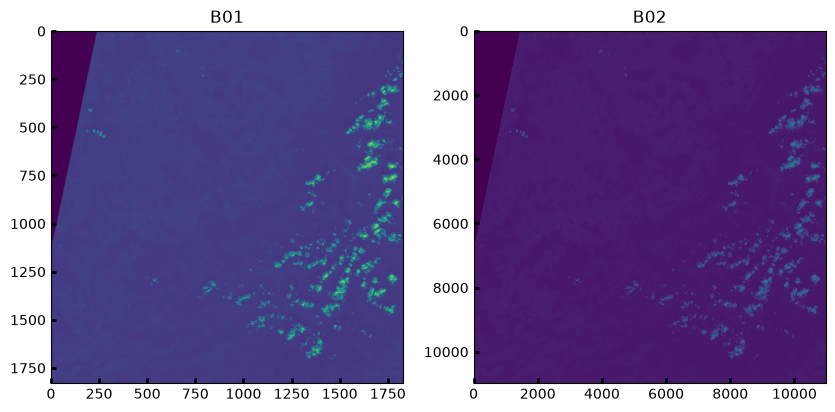

Minimum B01 value: 0 
Maximum B01 value: 13232

Minimum B02 value: 0 
Maximum B02 value: 27939


In [4]:
b1 = b1_src.read(1) # rasterio.open does not load the whole data in RAM.
b2 = b2_src.read(1) # the read method does, taking the id of the spectral band to read as input (starting from 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 10))
ax[0].imshow(b1)
ax[0].set_title("B01")
ax[1].imshow(b2)
ax[1].set_title("B02")
plt.show()

print(f"Minimum B01 value: {b1.min()} \nMaximum B01 value: {b1.max()}\n")
print(f"Minimum B02 value: {b2.min()} \nMaximum B02 value: {b2.max()}")

#### Top of Atmosphere reflectance data

The Level-1C product provides top-of-atmosphere (TOA) reflectance images. In order to convert the raw images provided in digital numbers in reflectance data, the following formula must be applied:
$$\mathrm{L1C\_TOA} = \frac{\mathrm{L1C\_DN} + \mathrm{RADIO\_ADD\_OFFSET}}{\mathrm{QUANTIFICATION\_VALUE}}$$

The radiometric offset and the quantification value are used to store the reflectance data (floats) into 16 bits integers (therefore using less memory).

The values of radiometric offsets and of the quantification value are given in the MTD_MSIL1C.xml file. The `parse_MTD_MSI` function defined in the `auxiliary_data/parse_sentinel2_aux_data.py` file reads the file and returns a dictionary.

In [5]:
from eodal_s2_parsing import parse_MTD_MSI

metadata = parse_MTD_MSI(os.path.join(data_folder, 'MTD_MSIL1C.xml'))
plot_dict(metadata)

,type,value_preview
key,,
PRODUCT_URI,str,'S2B_MSIL1C_20261005T102859_N0513_R108_T31UGP_...
PROCESSING_LEVEL,str,'Level-1C'
SENSING_ORBIT_NUMBER,str,'108'
SPACECRAFT_NAME,str,'Sentinel-2B'
SENSING_ORBIT_DIRECTION,str,'DESCENDING'
datatakeIdentifier,str,'GS2B_20261005T102859_050041_N05.13'
pdgs_baseline,str,'N0513'
reflectance_conversion,float,0.998304476697911
SOLAR_IRRADIANCE_B01,float,1874.3


In [6]:
import numpy as np

def DN_to_TOA_reflectance(raster: np.ndarray, offset: float, quantification_value: float, no_data: int = 0):
    """
    Converts raw data in digital numbers to top-of-atmosphere reflectance. Converts missing data into NaNs.
    
    Args:
        raster: WxH array, i.e. 1 spectral band in TOA reflectance
        offset: the radiometric offset of the corresponding band
        quantification_value: the quantification value used for the sensor
        no_data: value used for missing data
    """
    # <CORRECTION>
    raster = np.asarray(raster, np.float32)
    no_data_mask = raster == no_data
    # </CORRECTION>
    raster[no_data_mask] = np.nan
    # <CORRECTION>
    raster = (raster + offset) / quantification_value
    # </CORRECTION>
    return raster

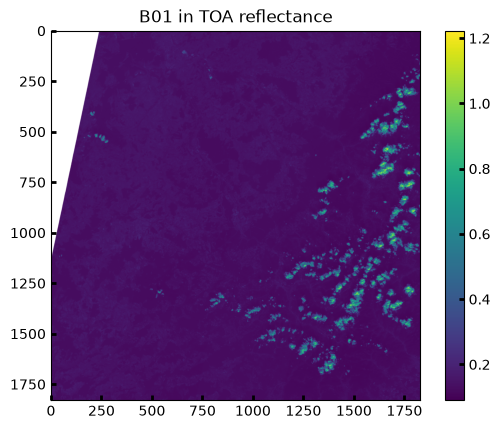

In [7]:
ref_b1 = DN_to_TOA_reflectance(
    # <CORRECTION>
    b1, metadata['RADIO_ADD_OFFSET_B01'], metadata['QUANTIFICATION_VALUE']
    # </CORRECTION>
)

fig = plt.figure()
plt.imshow(ref_b1)
plt.title("B01 in TOA reflectance")
plt.colorbar()
plt.show()

The range of reflectance is pulled up by the reflectance of clouds. Let us mask the clouds with the cloud mask provided in the `QI_DATA` folder.

In [8]:
mask_folder = glob.glob(os.path.join(data_folder, 'GRANULE/*/QI_DATA'))[0]
mask_classi = rasterio.open(os.path.join(mask_folder, 'MSK_CLASSI_B00.jp2'))

print(mask_classi.shape) 

(1830, 1830)


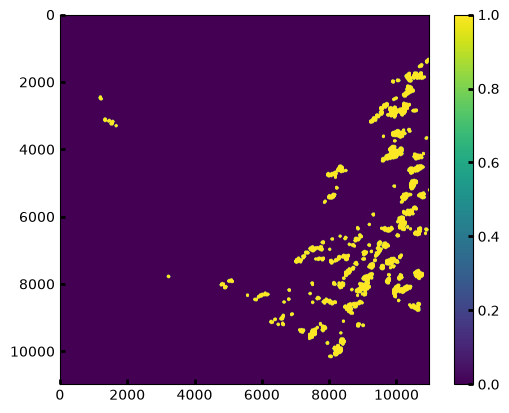

In [9]:
from skimage.transform import resize

upsample_mask_classi = resize(mask_classi.read(1), b2.shape, preserve_range=True)

fig = plt.figure()
plt.imshow(upsample_mask_classi)
plt.colorbar()
plt.show()

What does the `rgb_render` function do? Look in the `utils_.py` script.

In [10]:
def multi_band_DN_to_TOA_reflectance(rasters: np.ndarray, offsets: float, quantification_value: float, no_data: int = 0):
    """
    Converts multi-channel raw data in digital numbers to top-of-atmosphere reflectance. Converts missing data into NaNs.
    
    Args:
        rasters: list of WxH arrays, i.e. 1 spectral band in TOA reflectance
        offsets: list of the radiometric offsets of the corresponding bands
        quantification_value: the quantification value used for the sensor
        no_data: value used for missing data
    """
    outputs = []
    for raster, offset in zip(rasters, offsets):
        # <CORRECTION>
        raster = np.asarray(raster, np.float32)
        no_data_mask = raster == no_data
        raster[no_data_mask] = np.nan
        raster = (raster + offset) / quantification_value
        outputs.append(raster)
        # </CORRECTION>
    multi_bands_raster = np.stack(outputs)
    return multi_bands_raster

In [11]:
from utils.utils import rgb_render

rgb_bands = [
    # <CORRECTION>
    rasterio.open(os.path.join(img_folder, img_files['B04'])).read(1),
    rasterio.open(os.path.join(img_folder, img_files['B03'])).read(1),
    rasterio.open(os.path.join(img_folder, img_files['B02'])).read(1)
    # </CORRECTION>
]

rgb_offsets = [
    # <CORRECTION>
    metadata['RADIO_ADD_OFFSET_B04'],
    metadata['RADIO_ADD_OFFSET_B03'],
    metadata['RADIO_ADD_OFFSET_B02']
    # </CORRECTION>
]

rgb_img = multi_band_DN_to_TOA_reflectance(
    rgb_bands,
    rgb_offsets,
    metadata['QUANTIFICATION_VALUE']
)

# Mask clouds
rgb_img[:, upsample_mask_classi == 1] = np.nan
rgb_img, out_dmin, out_dmax = rgb_render(rgb_img)
print(out_dmin, out_dmax)

[0.0777 0.0493 0.0284] [0.161  0.1632 0.1932]


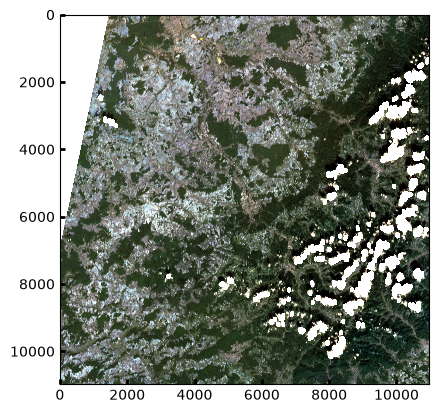

In [12]:
fig = plt.figure()
plt.imshow(rgb_img)
plt.show()

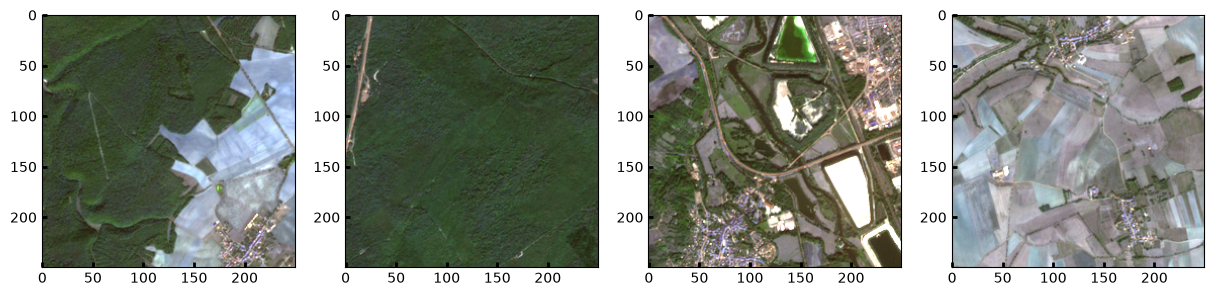

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(15, 8))
ax[0].imshow(rgb_img[1250:1500, 1500:1750])
ax[1].imshow(rgb_img[2250:2500, 1500:1750])
ax[2].imshow(rgb_img[1000:1250, 4500:4750])
ax[3].imshow(rgb_img[2250:2500, 3500:3750])
plt.show()

## From sun radiance to Bottom of Atmosphere irradiance

The conversion from the sensor measurement (numeric count) to radiance is performed as follows:
$$\mathrm{RADIANCE} = \frac{\mathrm{NUMERIC\_COUNT}}{A}$$
where $A$ is a sensor-dependent calibration coefficient. Then, the conversion from radiance to TOA reflectance is perfomed as:
$$\mathrm{TOA\_REFLECTANCE} = \frac{\pi \times \mathrm{RADIANCE}}{I_{sun} \times \text{cos} \: \theta_{sun}}$$
where $I_{sun}$ is the solar irradiance, and $\theta_{sun}$ is the sun zenith angle (https://sentiwiki.copernicus.eu/web/s2-processing). 

The solar irradiance used comes from measurements of the SOLSPEC spectrometer (Thuillier et al., 2003): <br>
    *Thuillier, G., Hersé, M., Labs, D. et al. The Solar Spectral Irradiance from 200 to 2400 nm as Measured by the SOLSPEC Spectrometer from the Atlas and Eureca Missions. Solar Physics 214, 1–22 (2003). https://doi.org/10.1023/A:1024048429145*

First, let's compare the solar irradiance of (Thuillier et al., 2003) with the solar irradiance we would have with a black-body radiation.

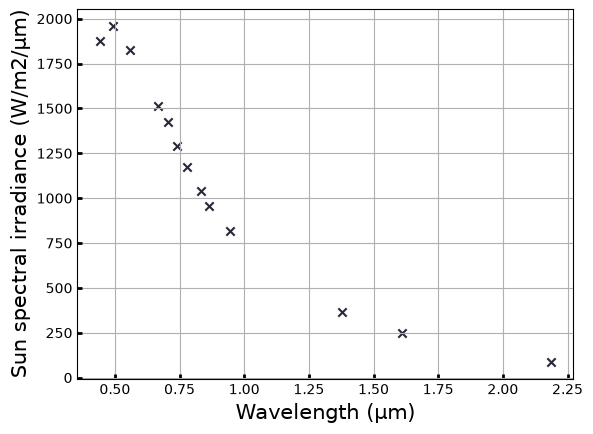

In [14]:
# Extract the solar irradiance of Thuillier 2003 from the `MTD_MSI_L1C.xml` file.
sun_irradiance_thuillier = [metadata[f'SOLAR_IRRADIANCE_{band}'] for band in S2_BANDS]
s2_central_wv = [metadata[f'WAVELENGTHS_{band}']['CENTRAL_WV'] / 1000 for band in S2_BANDS]

fig = plt.figure()
plt.scatter(s2_central_wv, sun_irradiance_thuillier, marker='x', color=COLORS['black'])
plt.xlabel(f'Wavelength (µm)', fontsize=fontsize)
plt.ylabel('Sun spectral irradiance (W/m2/µm)', fontsize=fontsize)
plt.grid()
plt.show()

Now, let's implement Planck's law.

In [15]:
CONSTANTS = {
    'Planck': 6.62607015e-34, # J.s
    'Boltzmann': 1.380649e-23, # J/K
    'c':  299792458, # m/s,
    'sun_radius': 696342e3, # m
    'earth_sun_distance': 149597870700 # m
}

def planck_law(wv: np.ndarray, T: float):
    """
    Plancks' Law.
    Args:
        wv: array of wavelengths in micrometers
        T: temperature in Kelvin
    """
    # <CORRECTION>
    wv = wv * 10**(-6) # convert in m
    A = 2 * CONSTANTS['Planck'] * CONSTANTS['c']**2 / wv**5
    B = CONSTANTS['Planck'] * CONSTANTS['c'] / (wv * CONSTANTS['Boltzmann'] * T)
    rad = A / (np.exp(B) - 1) # W/m2/sr/m
    return rad / 10**6 # W/m2/sr/µm
    # </CORRECTION>

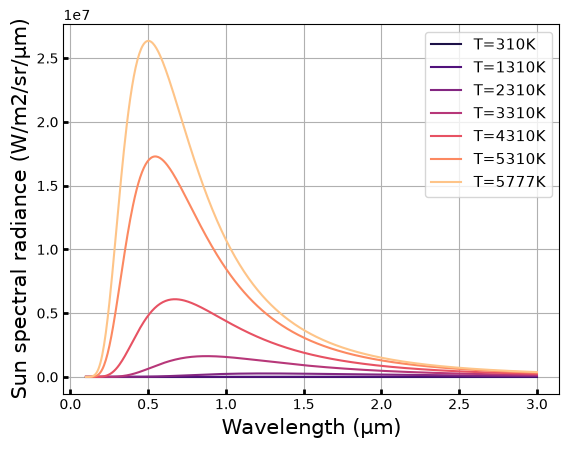

In [16]:
import seaborn as sns

temperatures = list(range(310, 6000, 1000)) + [5777]
colors = sns.color_palette("magma", len(temperatures))

wv = np.linspace(0.1, 3, 500) 

fig, ax = plt.subplots()

for i, T in enumerate(temperatures):
    # <CORRECTION>
    rad = planck_law(wv, T)
    plt.plot(wv, rad, color=colors[i], label=f'T={T}K')
    # </CORRECTION>
    
plt.xlabel(f'Wavelength (µm)', fontsize=fontsize)
plt.ylabel('Sun spectral radiance (W/m2/sr/µm)', fontsize=fontsize)
plt.legend(fontsize=int(0.75*fontsize))
plt.grid()
plt.show()

Compute the spectral irradiance at the top of the atmosphere, given the sun radius and the Earth - sun distance.

In [17]:
def top_of_atmosphere_irradiance(sun_radiance: np.ndarray):
    """ Computes the sun irradiance at the top-of-atmosphere for a surface orthogonal to the sun direction.
    Args:
        sun_radiance: the sun spectral radiance
    """
    # <CORRECTION>
    toa_irradiance = sun_radiance * np.pi * CONSTANTS['sun_radius']**2  / CONSTANTS['earth_sun_distance']**2
    # </CORRECTION>
    return toa_irradiance

In [18]:
solar_radiance = planck_law(wv, T=5777)
solar_irradiance = top_of_atmosphere_irradiance(solar_radiance)

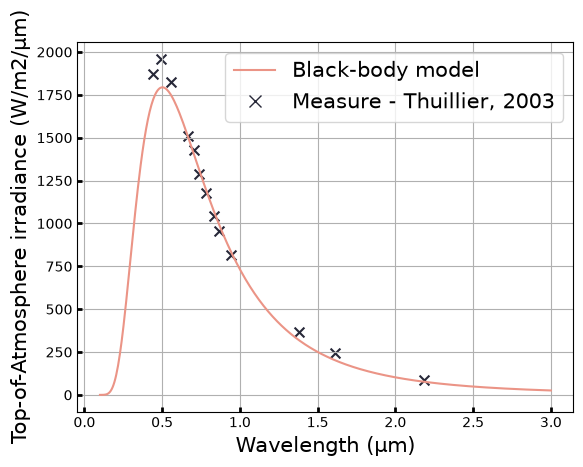

In [19]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots()
plt.plot(wv, solar_irradiance, color='#eb9486', label='Black-body model')
plt.scatter(s2_central_wv, sun_irradiance_thuillier, marker='x', s=50, color=COLORS['black'])
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], marker='x', linestyle='',
                      markerfacecolor=COLORS['black'], markeredgecolor=COLORS['black'],
                      markersize=9, label='Measure - Thuillier, 2003'))
plt.legend(handles=handles, fontsize=fontsize)
plt.xlabel(f'Wavelength (µm)', fontsize=fontsize)
plt.ylabel('Top-of-Atmosphere irradiance (W/m2/µm)', fontsize=fontsize)
plt.grid()

Now, in order to **convert the top-of-atmosphere reflectance to bottom-of-atmosphere reflectance**, we must take into account the BOA solar irradiance, which depends on the composition of the atmosphere. Metadata about the acquisition of the image, and auxiliary data about the atmospheric conditions are provided in the `AUX_DATA` folder. We are going to parse the medata files with Python.

In [20]:
from eodal_s2_parsing import parse_MTD_TL
from parse_auxiliary_data import get_atmosphere_data

aux_geometry_data = parse_MTD_TL(glob.glob(os.path.join(data_folder, 'GRANULE/*/MTD_TL.xml'))[0])

aux_atmosphere_data = get_atmosphere_data(
    data_folder,
    lat=aux_geometry_data['ULX'],
    lon=aux_geometry_data['ULY'])

aux_data = {
    'AUX_GEOMETRY_DATA': aux_geometry_data,
    'AUX_ATMOSPHERIC_DATA': aux_atmosphere_data
}

ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represent the step in h
                    Hint: try changing the step units
ECCODES ERROR   :  unable to represen

In [21]:
plot_dict(aux_geometry_data)

,type,value_preview
key,,
SCENE_ID,str,'S2B_OPER_MSI_L1C_TL_2BPS_20261005T140445_A050...
SENSING_TIME,str,'2026-10-05T10:37:37.699812Z'
NROWS_10m,int,10980
NCOLS_10m,int,10980
NROWS_20m,int,5490
NCOLS_20m,int,5490
NROWS_60m,int,1830
NCOLS_60m,int,1830
EPSG,int,32631


In [22]:
plot_dict(aux_atmosphere_data)

,type,value_preview
key,,
TOTAL_COLUMN_WATER_VAPOR,dict,"{'VALUE': 2.189050483703613, 'UNIT': 'g/cm2'}"
TOTAL_COLUMN_OZONE,dict,"{'VALUE': 0.28443839570614826, 'UNIT': 'Dobson..."
PRESSURE_AT_MEAN_SEA_LEVEL,dict,"{'VALUE': 102500.7890625, 'UNIT': 'Pa'}"
AOT_550,dict,"{'VALUE': 0.11772644519805908, 'UNIT': None}"


The total column ozone and the total column water vapor are used along with other uniform gas concentrations (CO2, CH4, N20...) in order to compute the transmittance of atmosphere due to **gas absorption**. The Aerosol Optical Thickness (AOD) at 550nm is used to compute the transmittance of atmosphere due to **aerosol scattering**, and the atmospheric pressure is used to compue the transmittance due to **molecular scattering**. 

We will use the **6S radiative transfer model** to compute several radiative and atmospheric quantities including the transmittance and the BOA irradiance: <br>
*E. F. Vermote, D. Tanre, J. L. Deuze, M. Herman and J. . -J. Morcette, "Second Simulation of the Satellite Signal in the Solar Spectrum, 6S: an overview," in IEEE Transactions on Geoscience and Remote Sensing, vol. 35, no. 3, pp. 675-686, May 1997, doi: 10.1109/36.581987.*

To run the 6S model with Python, we use the Py6S Python interface: https://github.com/robintw/Py6S.

At first, we are going to make a simulation on the spectrum from 0.4µm to 2.5µm.

In [23]:
from radiative_transfer_modeling import radiative_transfer_modeling_6S

wv = np.linspace(0.3, 2.5, 300)
radiative_variables = radiative_transfer_modeling_6S(aux_data, wv)
plot_dict(radiative_variables)

,type,value_preview
key,,
DIRECT_SOLAR_IRRADIANCE,dict,"{'VALUES': [0.193, 5.685, 25.948, 56.845, 92.0..."
DIFFUSE_SOLAR_IRRADIANCE,dict,"{'VALUES': [0.844, 19.966, 74.589, 136.118, 18..."
ENVIRONMENTAL_SOLAR_IRRADIANCE,dict,"{'VALUES': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
TRANSMITTANCE_TOTAL_SCATTERING_DOWNWARD,dict,"{'VALUES': [0.49851, 0.51417, 0.52993, 0.54579..."
TRANSMITTANCE_TOTAL_SCATTERING_UPWARD,dict,"{'VALUES': [0.63199, 0.64595, 0.65987, 0.67375..."
TRANSMITTANCE_TOTAL_GAS,dict,"{'VALUES': [0.00031, 0.04948, 0.32072, 0.66722..."
SPHERICAL_ALBEDO,dict,"{'VALUES': [0.49821, 0.46889, 0.44195, 0.41713..."
ATMOSPHERIC_INTRINSIC_RADIANCE,dict,"{'VALUES': [0.014, 2.064, 14.548, 32.959, 47.1..."
SOLAR_SPECTRUM,dict,"{'VALUES': [558.018, 559.038, 658.021, 774.415..."


In [24]:
I_dir = np.array(radiative_variables['DIRECT_SOLAR_IRRADIANCE']['VALUES'])
I_dif = np.array(radiative_variables['DIFFUSE_SOLAR_IRRADIANCE']['VALUES'])
I_TOA = np.array(radiative_variables['SOLAR_SPECTRUM']['VALUES'])
T_scat_up = np.array(radiative_variables['TRANSMITTANCE_TOTAL_SCATTERING_UPWARD']['VALUES'])
T_scat_down = np.array(radiative_variables['TRANSMITTANCE_TOTAL_SCATTERING_DOWNWARD']['VALUES'])
T_gas = np.array(radiative_variables['TRANSMITTANCE_TOTAL_GAS']['VALUES'])
R_atm = np.array(radiative_variables['ATMOSPHERIC_INTRINSIC_RADIANCE']['VALUES'])
S = np.array(radiative_variables['SPHERICAL_ALBEDO']['VALUES'])

From the outputs of the simulation, compute the total irradiance, and the total transmittance.

In [25]:
# <CORRECTION>
I_0 = I_dir + I_dif
T_up = T_scat_up * T_gas
T_down = T_scat_down * T_gas
# </CORRECTION>

From the TOA solar irradiance, compute the BOA solar irradiance given the transmittance of the atmosphere.

In [26]:
solar_radiance = planck_law(wv, T=5777)
solar_irradiance = top_of_atmosphere_irradiance(solar_radiance)

# <CORRECTION>
sun_zenith_angle = aux_geometry_data['SUN_ZENITH_ANGLE'] # degree
sun_zenith_angle = sun_zenith_angle * np.pi / 180 # rad
boa_irradiance_model = solar_irradiance * T_down * np.cos(sun_zenith_angle)
# </CORRECTION>

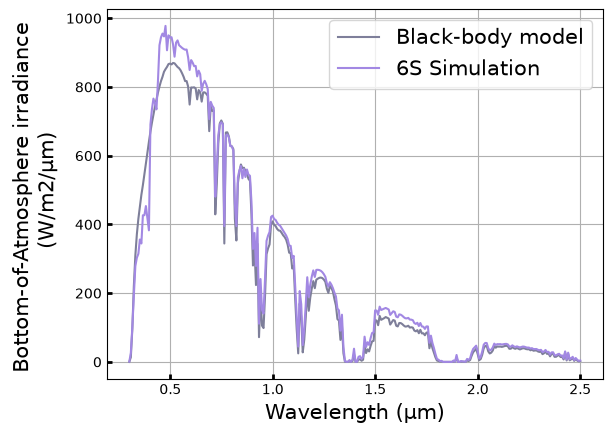

In [27]:
fig, ax = plt.subplots()
plt.plot(wv, boa_irradiance_model, label='Black-body model', color=COLORS['gray'])
plt.plot(wv, I_0, label='6S Simulation', color=COLORS['purple'])
plt.xlabel(f'Wavelength (µm)', fontsize=fontsize)
plt.ylabel('Bottom-of-Atmosphere irradiance \n (W/m2/µm)', fontsize=fontsize)
plt.legend(fontsize=fontsize)
plt.grid()

## From surface reflectance to top-of-atmosphere radiance

In this section, we start from the surface reflectance, and simulate sensor-level radiance.

In [28]:
reflectance_dict = {
    'tile': np.load('data/reflectance/tile.npy'),
    'grass': np.load('data/reflectance/grass.npy'),
    'dry_grass': np.load('data/reflectance/dry_grass.npy'),
    'mix_grass': np.load('data/reflectance/mix_grass.npy')
}

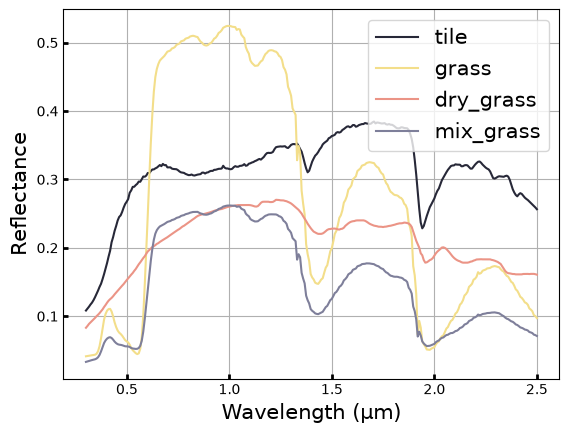

In [29]:
colors = list(COLORS.values())

fig, ax = plt.subplots()
for i, (material, refl) in enumerate(reflectance_dict.items()):
    plt.plot(wv, refl, color=colors[i], label=material)
plt.legend(fontsize=fontsize)
plt.xlabel(f'Wavelength (µm)', fontsize=fontsize)
plt.ylabel('Reflectance', fontsize=fontsize)
plt.grid()
plt.show()

Let's read and store the Sentinel-2 Spectral Function Response in an appropriate format.

In [30]:
s2_sfr = dict((band, metadata[f'SFR_{band}']) for band in S2_BANDS)
s2_sfr['B01']

{'VALUES': '0.0078788 0.05062229 0.18872241 0.45910654 0.7301606 0.84725949 0.8712359 0.88144835 0.89939274 0.91866943 0.93342075 0.94596319 0.95041031 0.95397234 0.96903168 0.99954617 1 0.97636807 0.96404957 0.95417544 0.92374483 0.88548879 0.80901627 0.60156114 0.30676603 0.10852771 0.03054209 0.00159257',
 'STEP': '1',
 'UNIT': 'nm'}

In [31]:
def compute_wv_from_metadata(wv: Dict, step: float):
    """Compute the wavelengths that correspond to the SFR.
    Args:
        wv: dict with keys 'MIN_WV' and 'MAX_WV'
        step: step in nm
    """
    # <CORRECTION>
    return (wv['MIN_WV'] + step * np.arange(wv['MAX_WV'] - wv['MIN_WV'] + 1)) / 1000 # µm
    # </CORRECTION>

In [32]:
for band, sfr in s2_sfr.items():
    s2_sfr[band]['sfr'] = [float(x) for x in sfr['VALUES'].split(' ')] # split the string in sfr['VALUES'] and convert to floats
    s2_sfr[band]['wv'] = compute_wv_from_metadata(metadata[f'WAVELENGTHS_{band}'], float(sfr['STEP']))

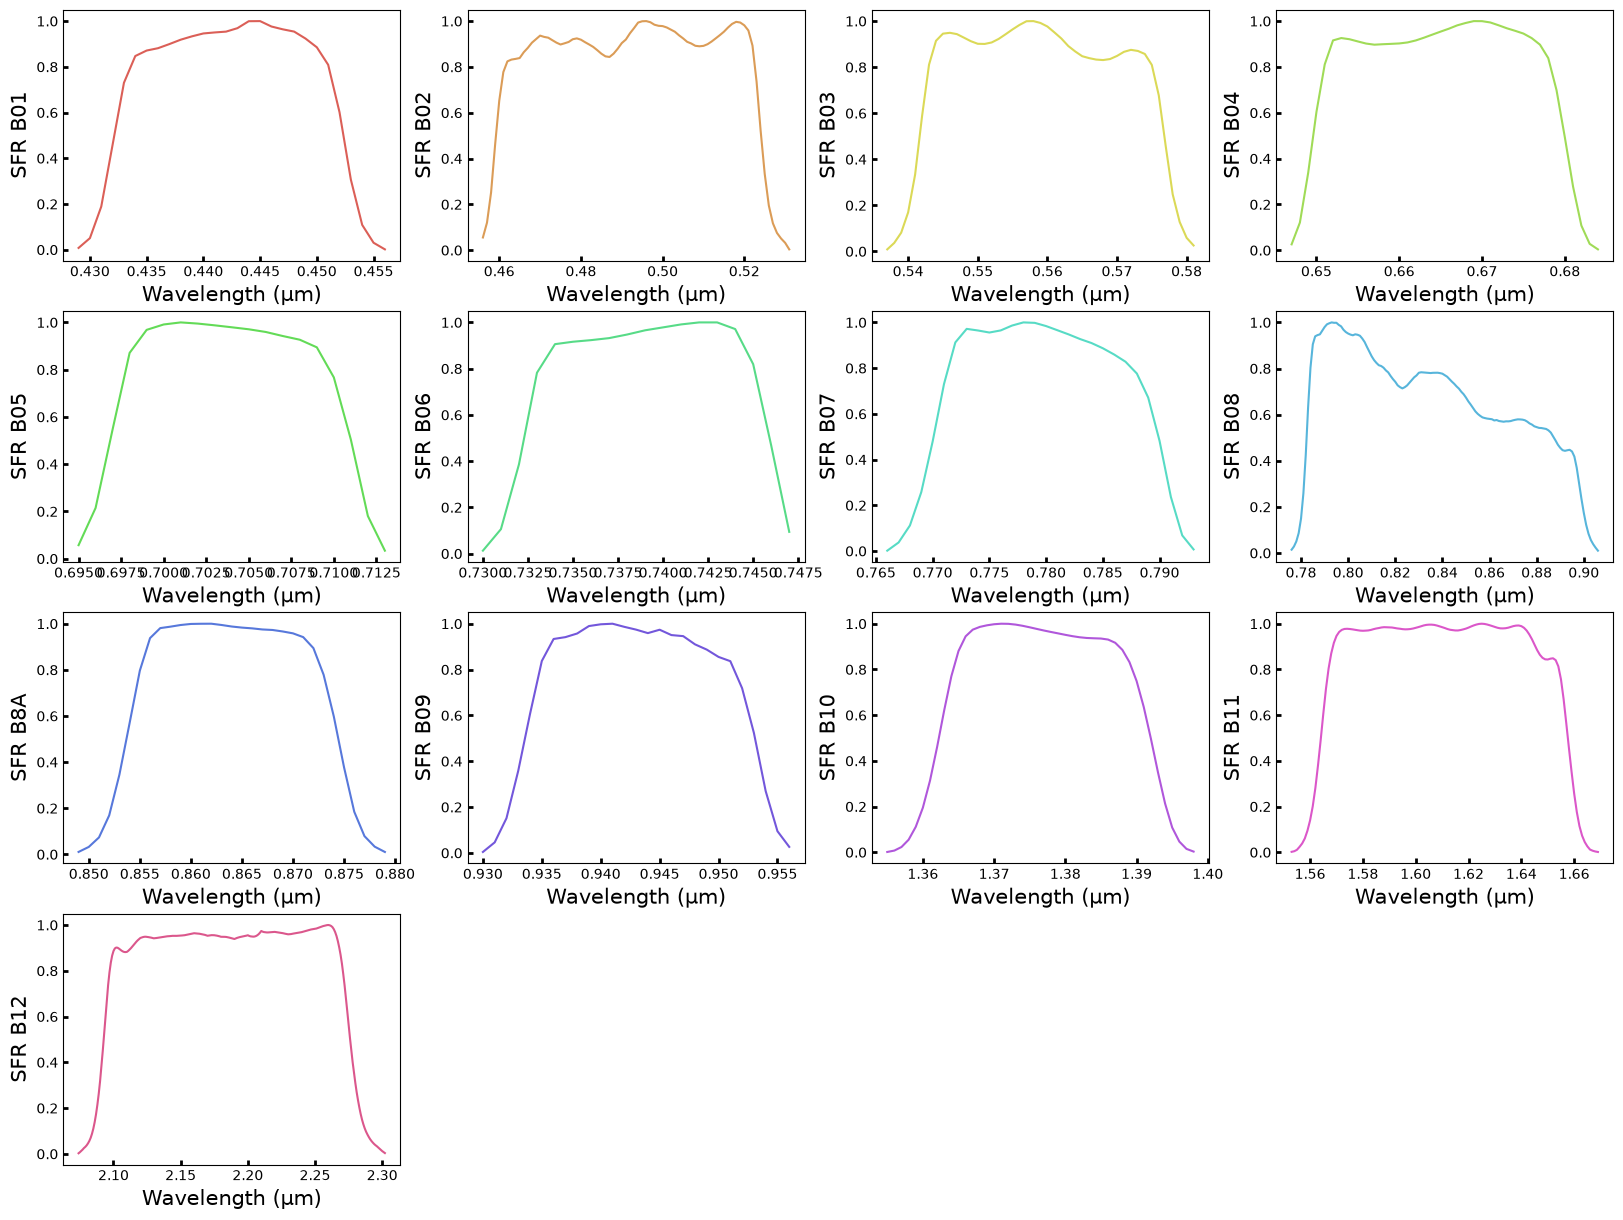

In [33]:
fig, axs = plt.subplots(4, 4, figsize=(20, 15))
colors = sns.color_palette("hls", len(S2_BANDS))
for i, (band, ax) in enumerate(zip(S2_BANDS, axs.flat)):
    ax.plot(s2_sfr[band]['wv'], s2_sfr[band]['sfr'], color=colors[i])
    ax.set_xlabel(f'Wavelength (µm)', fontsize=fontsize)
    ax.set_ylabel(f'SFR {band}', fontsize=fontsize)

for ax in axs.flat[len(S2_BANDS):]:
    ax.set_visible(False)
        
plt.show()

Let's build an array that contains the SFR of every band with wavelengths from 0.3 to 2.5 µm, to show the SFR on one figure only.

In [34]:
s2_sfr_array = np.zeros((len(s2_sfr), len(wv)))
for i, band in enumerate(s2_sfr):
    s2_sfr_array[i] = np.interp(
        # <CORRECTION>
        wv, s2_sfr[band]['wv'], 
        s2_sfr[band]['sfr'], 
        # </CORRECTION>
        left=0, 
        right=0)

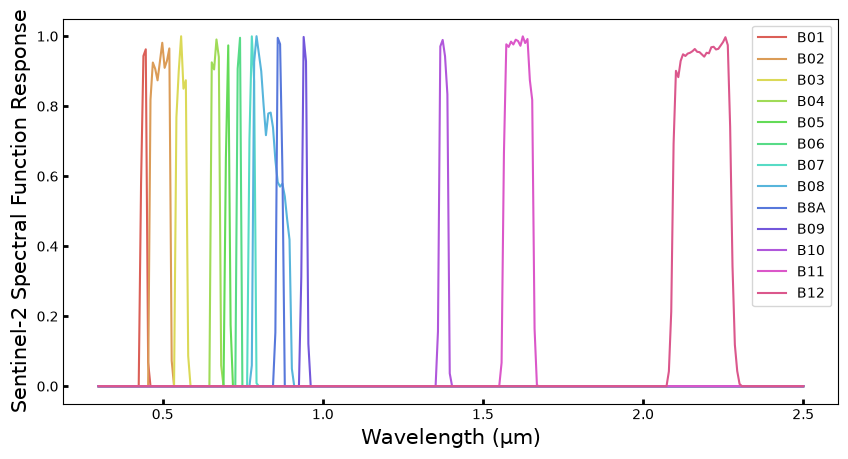

In [35]:
colors = sns.color_palette("hls", s2_sfr_array.shape[0])

fig, ax = plt.subplots(figsize=(10, 5))
for i in range(s2_sfr_array.shape[0]):
    plt.plot(wv, s2_sfr_array[i,:], color=colors[i], label=S2_BANDS[i])
plt.xlabel(f'Wavelength (µm)', fontsize=fontsize)
plt.ylabel('Sentinel-2 Spectral Function Response', fontsize=fontsize)
plt.legend()
plt.show()

Use the SFR to sample the reflectance spectra at the resolution of Sentinel-2.

In [36]:
def to_sentinel2_resolution(wv: np.ndarray, x: np.ndarray, s2_sfr: Dict, return_dict: bool = False):
    """
    Args:
        wv: original array of wavelengths, e.g. np.linspace(0.45, 2.5, 100)
        x: variable that is function of wv, e.g. reflectance(wv)
        s2_sfr: spectral function response of Sentinel-2
    """
    output_dict = {}
    for i, band in enumerate(s2_sfr):
        # <CORRECTION>
        x_on_sfr_wv = np.interp(s2_sfr[band]['wv'], wv, x)
        # </CORRECTION>
        num = np.trapezoid(
            # <CORRECTION>
            x_on_sfr_wv * s2_sfr[band]['sfr'], s2_sfr[band]['wv']
            # </CORRECTION>
        )
        den = np.trapezoid(s2_sfr[band]['sfr'], s2_sfr[band]['wv'])
        output_dict[band] = float(num /den)
    if return_dict:
        return output_dict
    else:
        output = np.array(list(output_dict.values()))
        return output

In [37]:
s2_reflectance_dict = {}

for mat, refl in reflectance_dict.items():
    s2_reflectance_dict[mat] = to_sentinel2_resolution(wv, refl, s2_sfr)

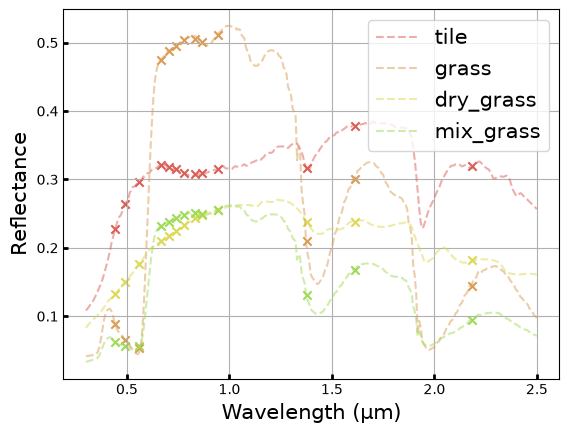

In [39]:
fig, ax = plt.subplots()
for i, ((material, s2_refl), refl) in enumerate(zip(s2_reflectance_dict.items(), reflectance_dict.values())):
    plt.plot(wv, refl, color=colors[i], linestyle='--', alpha=0.5, label=material)
    plt.scatter(s2_central_wv, s2_refl, color=colors[i], marker='x')
plt.legend(fontsize=fontsize)
plt.xlabel(f'Wavelength (µm)', fontsize=fontsize)
plt.ylabel('Reflectance', fontsize=fontsize)
plt.grid()
plt.show()

Implement a `reflectance_to_radiance` function that approximates the sensor-level radiance given the reflectance and atmospheric variables. Do not take into account the coupling and environmental irradiance terms.

In [40]:
def forward_model(
    reflectance: np.ndarray, 
    R_atm: np.ndarray, 
    I_0: np.ndarray,
    T_dir: np.ndarray,
    T_dif: np.ndarray,
    S: np.ndarray):
    """Forward model that approximates sensor-level radiance 
    given surface-level reflectance and atmospheric variables.
    """
    # <CORRECTION>
    I_tot = I_0 / (1 - reflectance * S)
    R_sensor = R_atm + (T_dir + T_dif) * I_tot / np.pi * reflectance
    # </CORRECTION>
    return R_sensor

Compute the direct and diffuse transmittance, that we will denote by T_dir and T_dif, respectively.

In [41]:
# <CORRECTION>
T_dir = I_dir / (I_TOA * np.cos(sun_zenith_angle))
T_dif = I_dif / (I_TOA * np.cos(sun_zenith_angle))
# </CORRECTION>

In [43]:
I_0_s2 = to_sentinel2_resolution(wv, I_0, s2_sfr)
T_dir_s2 = to_sentinel2_resolution(wv, T_dir, s2_sfr)
T_dif_s2 = to_sentinel2_resolution(wv, T_dif, s2_sfr)
R_atm_s2 = to_sentinel2_resolution(wv, R_atm, s2_sfr)
S_s2 = to_sentinel2_resolution(wv, S, s2_sfr)

toa_radiance_dict = {}
for material, s2_refl in s2_reflectance_dict.items():
    toa_radiance_dict[material] = forward_model(s2_refl, R_atm_s2, I_0_s2, T_dir_s2, T_dif_s2, S_s2)

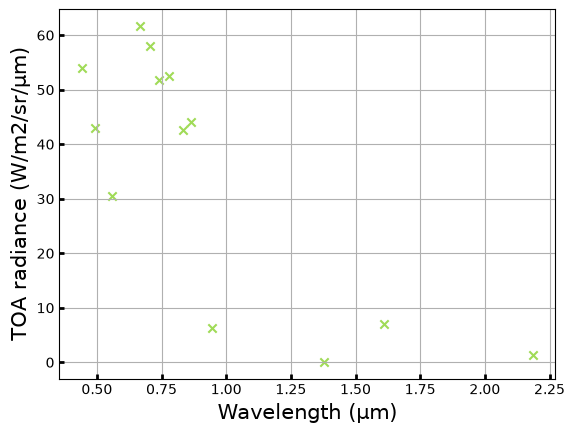

In [44]:
fig, ax = plt.subplots()
plt.scatter(s2_central_wv, toa_radiance_dict['mix_grass'], color=colors[i], marker='x')
plt.xlabel(f'Wavelength (µm)', fontsize=fontsize)
plt.ylabel('TOA radiance (W/m2/sr/µm)', fontsize=fontsize)
plt.grid()
plt.show()

Let's compare to a true measurement. Complete the `stack_bands` function that stacks bands of different spatial resolution together, with an optional spatial window in the format (col_offset, row_offset, n_cols, n_rows).

In [45]:
from rasterio.windows import Window
from rasterio.enums import Resampling


def stack_bands(
    img_folder: str,
    img_files: Dict,
    bands: list,
    metadata: Dict,
    cloud_mask: np.ndarray = None,
    window = None,
    no_data: int = 0):
    """Load and stack several bands by upsampling the rasters to the highest resolution.
    Args:
        img_folder: path to the image folder
        img_files: dict that contains the image path, e.g. 'B01': 'path_B01.jp2'
        bands: list of a subset of bands, e.g. ['B01', 'B02', 'B03']
        metadata: dict that contains metadat about the radiometric offsets and quantification value
        cloud_mask: an optional cloud mask at the highest spatial resolution
        window: an optional tuple to select a spatial subset of the image (col_offset, row_offset, n_cols, n_rows)
            defined at the highest spatial resolution
        no_data: value of missing data
    """
    multibands_raster = []
    for band in bands:
        # <CORRECTION>
        raster = rasterio.open(os.path.join(img_folder, img_files[band]))
        # </CORRECTION>
        multibands_raster.append(raster)

    shapes = [raster.shape for raster in multibands_raster]
    out_shapes = sorted(shapes, key=lambda x: x[0])
    out_shape = out_shapes[-1]
    # <CORRECTION>
    factor_shape = [out_shape[0] // shape[0] for shape in shapes] 
    # </CORRECTION>
    
    if window is not None:
        windows = [Window(window[0] // factor, window[1] // factor, window[2] // factor, window[3] // factor) for factor in factor_shape]
        out_shape = (window[2], window[3])
    else:
        windows = [None] * len(shapes)

    # <CORRECTION>
    multibands_raster = [
        raster.read(
            1, 
            out_shape=(1,) + out_shape,
            resampling=Resampling.bilinear, 
            window=window
        ) for raster, window in zip(multibands_raster, windows)
    ]

    multibands_raster = [raster + metadata[f'RADIO_ADD_OFFSET_{band}'] for raster, band in zip(multibands_raster, bands)]
    multibands_raster = np.stack(multibands_raster)
    multibands_raster /= metadata['QUANTIFICATION_VALUE']

    no_data_mask = np.any(multibands_raster == no_data, axis=0)
    multibands_raster[:, no_data_mask] = np.nan

    if cloud_mask is not None:
        multibands_raster[:, cloud_mask] = np.nan

    # <CORRECTION>

    return multibands_raster

Let's compare the sensor-level radiance of a vegetated area measured by Sentinel-2 with a spectrum of grass.

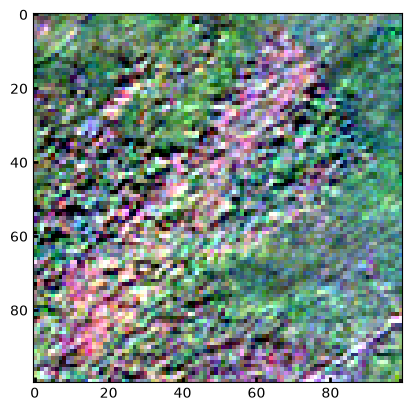

In [46]:
window = (1620, 2370, 100, 100)
raster = stack_bands(img_folder, img_files, S2_BANDS, metadata, window=window)
rgb = raster[1:4]

rgb_compo, _, _ = rgb_render(rgb)
plt.imshow(rgb_compo)
plt.show()

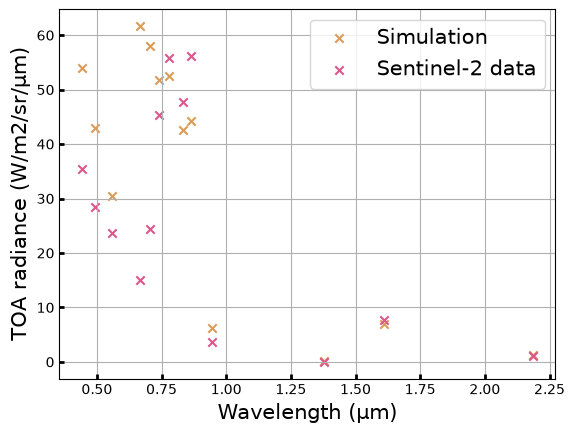

In [50]:
pixel_toa_reflectance = np.mean(raster, axis=(1, 2))
pixel_toa_radiance = pixel_toa_reflectance * I_0_s2 / np.pi

fig, ax = plt.subplots()
plt.scatter(s2_central_wv, toa_radiance_dict['mix_grass'], color=colors[1], marker='x', label='Simulation')
plt.scatter(s2_central_wv, pixel_toa_radiance, color=colors[-1], marker='x', label='Sentinel-2 data')
plt.xlabel(f'Wavelength (µm)', fontsize=fontsize)
plt.ylabel('TOA radiance (W/m2/sr/µm)', fontsize=fontsize)
plt.grid()
plt.legend(fontsize=fontsize)
plt.show()

## From top-of-atmosphere radiance to surface reflectance

Now, we will do the other way around. We are going to perform a simplified atmospheric correction, and compare the estimated surface reflectance with the L2A product of Sentinel-2. 

We are going to use a subset of the image.

In [51]:
window = (1750, 2370, 1000, 1000)
raster = stack_bands(img_folder, img_files, S2_BANDS, metadata, window=window)

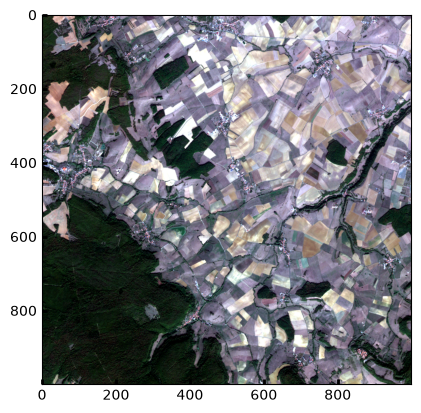

In [52]:
rgb_compo, _, _ = rgb_render(raster[1:4])
plt.imshow(rgb_compo)
plt.show()

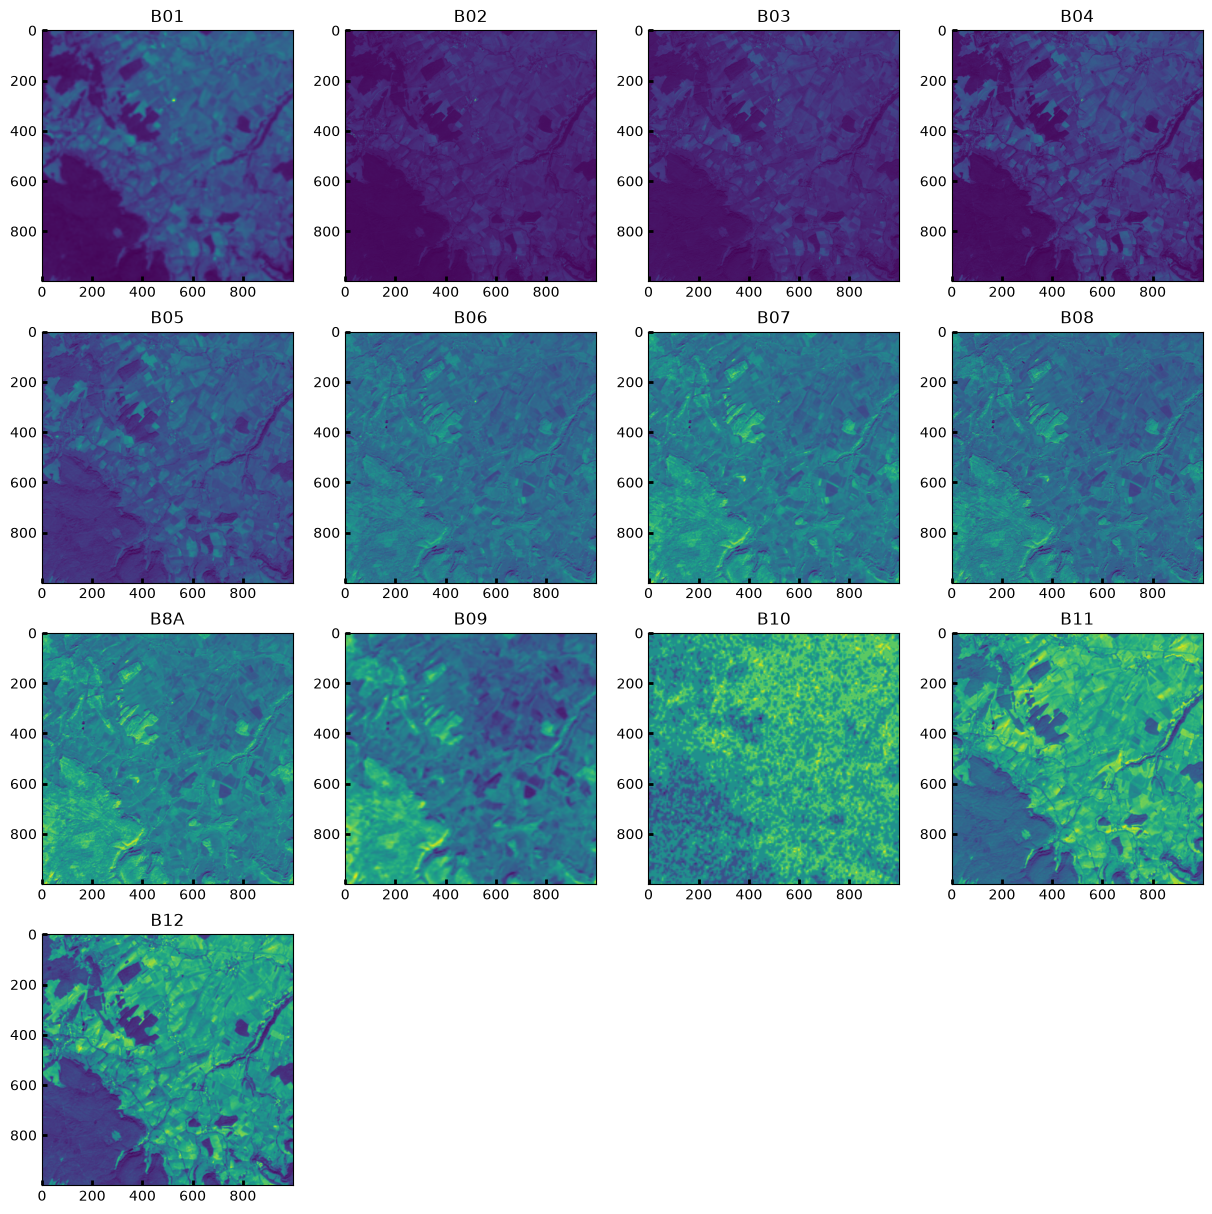

In [53]:
fig, axs = plt.subplots(4, 4, figsize=(15, 15))

for band, ax in zip(range(raster.shape[0]), axs.flat):
    ax.imshow(raster[band])
    ax.set_title(S2_BANDS[band])
for ax in axs.flat[raster.shape[0]:]:
    ax.set_visible(False)
plt.show()

Let us convert the TOA reflectance to TOA radiance.

In [54]:
# <CORRECTION>
raster_toa_rad = raster * np.array(sun_irradiance_thuillier).reshape(-1, 1, 1) * np.cos(sun_zenith_angle) / np.pi
# </CORRECTION>

In [55]:
def inverse_model(
    R_sensor: np.ndarray,
    R_atm: np.ndarray,
    T_dir: np.ndarray,
    T_dif: np.ndarray,
    S: np.ndarray,
    I_0: np.ndarray):
    """Inverse model that performs a simplified atmospheric correction.
    Args:
        R_sensor: TOA radiance measured by the sensor
        R_atm: TOA radiance scattered by atmosphere without interaction with Earth
        T_dir: direct transmittance
        T_dif: diffuse transmittance
        S: spherical albedo
        I_0: total BOA sun irradiance without interaction with Earth
    """
    R_atm = R_atm.reshape(-1, 1, 1)
    S = S.reshape(-1, 1, 1)
    # <CORRECTION>
    num = R_sensor - R_atm
    T_tot = (T_dir + T_dif).reshape(-1, 1, 1)
    I_0 = I_0.reshape(-1, 1, 1)
    den = num * S + T_tot * I_0 / np.pi
    return num / den
    # </CORRECTION>

Let's load the outputs of the 6S simulation for the resolution of Sentinel-2.

In [56]:
radiative_variables = radiative_transfer_modeling_6S(aux_data, s2_central_wv)
plot_dict(radiative_variables)

,type,value_preview
key,,
DIRECT_SOLAR_IRRADIANCE,dict,"{'VALUES': [570.171, 702.277, 721.774, 703.077..."
DIFFUSE_SOLAR_IRRADIANCE,dict,"{'VALUES': [283.294, 247.99, 179.764, 118.822,..."
ENVIRONMENTAL_SOLAR_IRRADIANCE,dict,"{'VALUES': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
TRANSMITTANCE_TOTAL_SCATTERING_DOWNWARD,dict,"{'VALUES': [0.78067, 0.8343, 0.87995, 0.91971,..."
TRANSMITTANCE_TOTAL_SCATTERING_UPWARD,dict,"{'VALUES': [0.86441, 0.902, 0.93222, 0.95704, ..."
TRANSMITTANCE_TOTAL_GAS,dict,"{'VALUES': [0.99804, 0.98519, 0.92595, 0.96264..."
SPHERICAL_ALBEDO,dict,"{'VALUES': [0.18899, 0.1424, 0.10157, 0.06626,..."
ATMOSPHERIC_INTRINSIC_RADIANCE,dict,"{'VALUES': [40.919, 28.97, 16.114, 7.895, 6.00..."
SOLAR_SPECTRUM,dict,"{'VALUES': [1859.999, 1953.642, 1827.048, 1555..."


In [57]:
wv = np.array(radiative_variables['WAVELENGTHS']['VALUES'])
I_dir = np.array(radiative_variables['DIRECT_SOLAR_IRRADIANCE']['VALUES'])
I_dif = np.array(radiative_variables['DIFFUSE_SOLAR_IRRADIANCE']['VALUES'])
I_TOA = np.array(radiative_variables['SOLAR_SPECTRUM']['VALUES'])
T_scat_up = np.array(radiative_variables['TRANSMITTANCE_TOTAL_SCATTERING_UPWARD']['VALUES'])
T_scat_down = np.array(radiative_variables['TRANSMITTANCE_TOTAL_SCATTERING_DOWNWARD']['VALUES'])
T_gas = np.array(radiative_variables['TRANSMITTANCE_TOTAL_GAS']['VALUES'])
R_atm = np.array(radiative_variables['ATMOSPHERIC_INTRINSIC_RADIANCE']['VALUES'])
S = np.array(radiative_variables['SPHERICAL_ALBEDO']['VALUES'])

In [58]:
# Compute I_0, T_dir and T_dif
# <CORRECTION>
I_0 = I_dir + I_dif
T_dir = I_dir / (I_TOA * np.cos(sun_zenith_angle))
T_dif = I_dif / (I_TOA * np.cos(sun_zenith_angle))
# </CORRECTION>

surface_reflectance = inverse_model(
    raster_toa_rad,
    R_atm,
    T_dir,
    T_dif,
    S,
    I_0
)

Now, let us load the L2A product to compare with our estimation.

In [60]:
import re

L2A_S2_BANDS = ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12']
L2A_data_folder = '../../../../data/S2B_MSIL2A_20261005T102859_N0513_R108_T31UGP_20261005T142235.SAFE/'
L2A_img_folder = glob.glob(os.path.join(L2A_data_folder, 'GRANULE/*/IMG_DATA'))[0]
L2A_img_folders = os.listdir(L2A_img_folder)
L2A_img_files = dict((L2A_img_folders[i], os.listdir(os.path.join(L2A_img_folder, L2A_img_folders[i]))) for i in range(len(L2A_img_folders)))

L2A_band_paths = {}
for key in sorted(L2A_img_files, key=lambda k: int(k[1:-1]))[::-1]:
    for filename in L2A_img_files[key]:
        band = re.search(r'_(.+?)_\d+m\.jp2', filename).group(1)
        if band not in L2A_band_paths:
            L2A_band_paths[band.split('_')[-1]] = f'{key}/{filename}'
L2A_band_paths

{'B04': 'R10m/T31UGP_20261005T102859_B04_10m.jp2',
 'B12': 'R20m/T31UGP_20261005T102859_B12_20m.jp2',
 'SCL': 'R20m/T31UGP_20261005T102859_SCL_20m.jp2',
 'B8A': 'R20m/T31UGP_20261005T102859_B8A_20m.jp2',
 'B06': 'R20m/T31UGP_20261005T102859_B06_20m.jp2',
 'B11': 'R20m/T31UGP_20261005T102859_B11_20m.jp2',
 'B01': 'R20m/T31UGP_20261005T102859_B01_20m.jp2',
 'B03': 'R10m/T31UGP_20261005T102859_B03_10m.jp2',
 'B07': 'R20m/T31UGP_20261005T102859_B07_20m.jp2',
 'B09': 'R60m/T31UGP_20261005T102859_B09_60m.jp2',
 'TCI': 'R10m/T31UGP_20261005T102859_TCI_10m.jp2',
 'B02': 'R10m/T31UGP_20261005T102859_B02_10m.jp2',
 'WVP': 'R10m/T31UGP_20261005T102859_WVP_10m.jp2',
 'AOT': 'R10m/T31UGP_20261005T102859_AOT_10m.jp2',
 'B05': 'R20m/T31UGP_20261005T102859_B05_20m.jp2',
 'B08': 'R10m/T31UGP_20261005T102859_B08_10m.jp2'}

In [61]:
window = (1750, 2370, 1000, 1000)
L2A_raster = stack_bands(L2A_img_folder, L2A_band_paths, L2A_S2_BANDS, metadata, window=window)
# remove B10 that is not in L2A products
# <CORRECTION>
surface_reflectance = np.concatenate((surface_reflectance[:10], surface_reflectance[11:]), axis=0)
# </CORRECTION>

In [62]:
hat_L2A_rgb_compo, _, _ = rgb_render(surface_reflectance[1:4])
true_L2A_rgb_compo, _, _ = rgb_render(L2A_raster[1:4])
absolute_error = np.abs((surface_reflectance - L2A_raster))

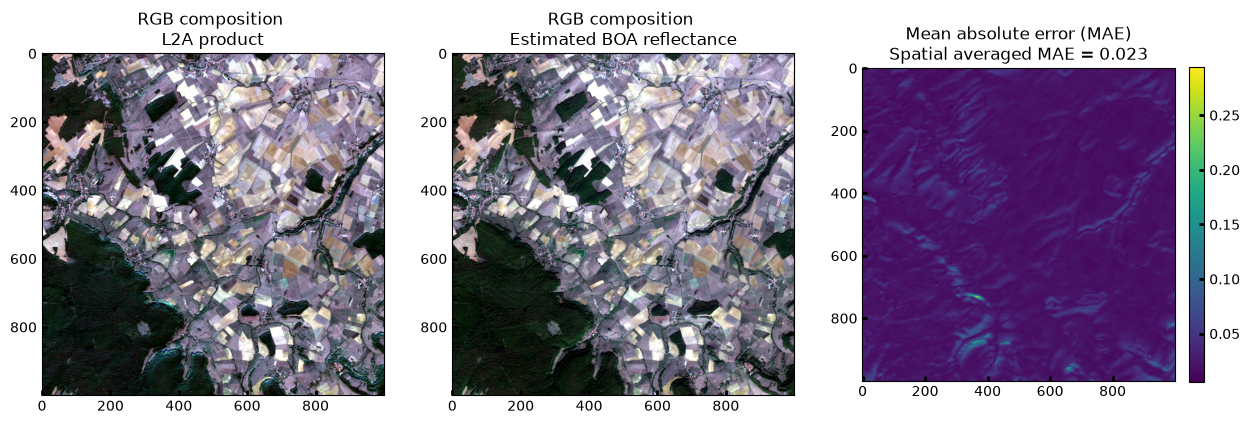

In [64]:
fig, ax = plt.subplots(1, 3, figsize=(15, 10))

ax[0].imshow(true_L2A_rgb_compo)
ax[0].set_title('RGB composition \nL2A product')

ax[1].imshow(hat_L2A_rgb_compo)
ax[1].set_title('RGB composition \nEstimated BOA reflectance')

im2 = ax[2].imshow(absolute_error.mean(axis=0))
ax[2].set_title('Mean absolute error (MAE)\nSpatial averaged MAE = {:.3f}'.format(absolute_error.mean()))
fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04)

plt.show()

Where are the largest errors?

In [68]:
### <CORRECTION> ###
import re
# transformation de cet énoncé en version étudiante

fname = "basics_radiative_transfer_modeling_correction.ipynb" # ce fichier
fout  = fname.replace("_correction","")

# print("Fichier de sortie: ", fout )

f = open(fname, "r")
txt = f.read()

f.close()

f2 = open(fout, "w")
f2.write(re.sub("<CORRECTION>.*?(</CORRECTION>)"," TODO ",\
    txt, flags=re.DOTALL))
f2.close()

### </CORRECTION> ###